<a href="https://colab.research.google.com/github/Devil-92/100_Days_of_ML/blob/main/HyperparameterOptimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

>So, what is this hyper-parameter optimization? Suppose
there is a simple pipeline for your machine learning project. There is a dataset, you
directly apply a model, and then you have results. The parameters that the model
has here are known as hyper-parameters, i.e. the parameters that control the
training/fitting process of the model. If we train a linear regression with SGD,
parameters of a model are the slope and the bias and hyperparameter is learning
rate.

In [1]:
from sklearn import linear_model
model = linear_model.LogisticRegression()

In [2]:
model.get_params()

{'C': 1.0,
 'class_weight': None,
 'dual': False,
 'fit_intercept': True,
 'intercept_scaling': 1,
 'l1_ratio': None,
 'max_iter': 100,
 'multi_class': 'deprecated',
 'n_jobs': None,
 'penalty': 'l2',
 'random_state': None,
 'solver': 'lbfgs',
 'tol': 0.0001,
 'verbose': 0,
 'warm_start': False}

In [3]:
from sklearn import ensemble
model = ensemble.RandomForestRegressor()

In [4]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

In [5]:
len(model.get_params())

18

In [14]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [17]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iabhishekofficial/mobile-price-classification")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mobile-price-classification' dataset.
Path to dataset files: /kaggle/input/mobile-price-classification


In [20]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/Projects/Mobile Price Pred/train.csv')

In [21]:
df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


## Grid Search

A search over
this grid to find the best combination of parameters is known as grid search.

In [19]:
import os
open('rf_grid.py' , 'a').close()

In [24]:
%%writefile rf_grid.py
import numpy as np
import pandas as pd

from sklearn import ensemble
from sklearn import metrics
from sklearn import model_selection

if __name__ == '__main__' :
  df = pd.read_csv('/content/drive/MyDrive/Projects/Mobile Price Pred/train.csv')

  X = df.drop('price_range' , axis = 1)

  y = df.price_range

  classifier = ensemble.RandomForestClassifier(n_jobs = -1)

  param_grid = {
      'n_estimators' : [100 , 200 , 250 , 300 , 400 , 500] ,
      'max_depth' : [1 , 2 , 5 , 7 , 11 , 15] ,
      'criterion' : ['gini' , 'entropy']
  }

  model = model_selection.GridSearchCV(
      estimator = classifier ,
      param_grid = param_grid ,
      scoring = 'accuracy' ,
      verbose = 10 ,
      n_jobs = 1 ,
      cv = 5
  )

  model.fit(X , y)

  print(f"Best score of the model : {model.best_score_}")

  print(model.best_estimator_.get_params())

Overwriting rf_grid.py


In [25]:
! python rf_grid.py

Fitting 5 folds for each of 72 candidates, totalling 360 fits
[CV 1/5; 1/72] START criterion=gini, max_depth=1, n_estimators=100..............
[CV 1/5; 1/72] END criterion=gini, max_depth=1, n_estimators=100;, score=0.578 total time=   0.3s
[CV 2/5; 1/72] START criterion=gini, max_depth=1, n_estimators=100..............
[CV 2/5; 1/72] END criterion=gini, max_depth=1, n_estimators=100;, score=0.585 total time=   0.3s
[CV 3/5; 1/72] START criterion=gini, max_depth=1, n_estimators=100..............
[CV 3/5; 1/72] END criterion=gini, max_depth=1, n_estimators=100;, score=0.578 total time=   0.3s
[CV 4/5; 1/72] START criterion=gini, max_depth=1, n_estimators=100..............
[CV 4/5; 1/72] END criterion=gini, max_depth=1, n_estimators=100;, score=0.593 total time=   0.3s
[CV 5/5; 1/72] START criterion=gini, max_depth=1, n_estimators=100..............
[CV 5/5; 1/72] END criterion=gini, max_depth=1, n_estimators=100;, score=0.573 total time=   0.3s
[CV 1/5; 2/72] START criterion=gini, max_de

## Randomized Search

In random search, we randomly select a combination of parameters and
calculate the cross-validation score. The time consumed here is less than grid search
because we do not evaluate over all different combinations of parameters. We
choose how many times we want to evaluate our models, and that’s what decides
how much time the search takes.

if param_distributions has all the values as list, random search will be done by sampling without replacement if any of the parameters come from a distribution, random search uses sampling with replacement

In [26]:
open('rf_random_search.py' , 'a').close()

In [32]:
%%writefile rf_random_search.py
import numpy as np
import pandas as pd

from sklearn import metrics
from sklearn import model_selection
from sklearn import ensemble

if __name__ == '__main__' :

  df = pd.read_csv('/content/drive/MyDrive/Projects/Mobile Price Pred/train.csv')
  X = df.drop('price_range' , axis = 1)
  y = df.price_range

  param_grid = {
      "n_estimators" : np.arange(100 , 1500 , 100) ,
      'max_depth' : np.arange(1 , 31) ,
      'criterion' : ['gini' , 'entropy']
  }

  classifier = ensemble.RandomForestClassifier(n_jobs = -1)

  model = model_selection.RandomizedSearchCV(
      estimator = classifier ,
      param_distributions = param_grid ,
      n_iter = 20 ,
      scoring = 'accuracy' ,
      n_jobs = 1 ,
      verbose = 10 ,
      cv = 5
  )

  model.fit(X , y)

  print(f"Best score so far {model.best_score_}")

  print(model.best_estimator_.get_params())

Overwriting rf_random_search.py


In [33]:
! python rf_random_search.py

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV 1/5; 1/20] START criterion=entropy, max_depth=1, n_estimators=200...........
[CV 1/5; 1/20] END criterion=entropy, max_depth=1, n_estimators=200;, score=0.583 total time=   0.5s
[CV 2/5; 1/20] START criterion=entropy, max_depth=1, n_estimators=200...........
[CV 2/5; 1/20] END criterion=entropy, max_depth=1, n_estimators=200;, score=0.530 total time=   0.5s
[CV 3/5; 1/20] START criterion=entropy, max_depth=1, n_estimators=200...........
[CV 3/5; 1/20] END criterion=entropy, max_depth=1, n_estimators=200;, score=0.537 total time=   0.5s
[CV 4/5; 1/20] START criterion=entropy, max_depth=1, n_estimators=200...........
[CV 4/5; 1/20] END criterion=entropy, max_depth=1, n_estimators=200;, score=0.580 total time=   0.5s
[CV 5/5; 1/20] START criterion=entropy, max_depth=1, n_estimators=200...........
[CV 5/5; 1/20] END criterion=entropy, max_depth=1, n_estimators=200;, score=0.552 total time=   0.5s
[CV 1/5; 2/20] START criteri

## GP Minimize

When we go into advanced hyperparameter optimization techniques, we can take a
look at minimization of functions using different kinds of minimization
algorithms. This can be achieved by using many minimization functions such as
downhill simplex algorithm, Nelder-Mead optimization, using a Bayesian
technique with Gaussian process for finding optimal parameters or by using a
genetic algorithm. I will talk more about the application of downhill simplex and
Nelder-Mead in ensembling and stacking chapter. First, let’s see how the gaussian
process can be used for hyper-parameter optimization. These kinds of algorithms
need a function they can optimize. Most of the time, it’s about the minimization of
this function, like we minimize loss.

So, let’s say, you want to find the best parameters for best accuracy and obviously,
the more the accuracy is better. Now we cannot minimize the accuracy, but we can
minimize it when we multiply it by -1. This way, we are minimizing the negative
of accuracy, but in fact, we are maximizing accuracy. Using Bayesian
optimization with gaussian process can be accomplished by using gp_minimize
function from scikit-optimize (skopt) library.

In [35]:
open('rf_gp_minimize.py' , 'a').close()

In [45]:
%%writefile rf_gp_minimize.py
import pandas as pd
import numpy as np

from functools import partial

from sklearn import ensemble
from sklearn import model_selection
from sklearn import metrics

from skopt import gp_minimize
from skopt import space

def optimize(params , param_names , x , y) :
  params = dict(zip(param_names , params))

  model = ensemble.RandomForestClassifier(**params)

  kf = model_selection.StratifiedKFold(n_splits = 5)

  accuracies = []

  for idx in kf.split(X=x , y=y) :

    train_idx , test_idx = idx[0] , idx[1]

    xtrain = x.iloc[train_idx]
    ytrain = y.iloc[train_idx]

    xtest = x.iloc[test_idx]
    ytest = y.iloc[test_idx]

    model.fit(xtrain , ytrain)

    preds = model.predict(xtest)

    fold_accuracy = metrics.accuracy_score(
        ytest ,
        preds
    )

    accuracies.append(fold_accuracy)

  return -1 * np.mean(accuracies)

if __name__ == '__main__' :
  df = pd.read_csv('/content/drive/MyDrive/Projects/Mobile Price Pred/train.csv')

  X = df.drop('price_range' , axis = 1)

  y = df.price_range

  param_space = [
      space.Integer(3 , 15 , name = 'max_depth') ,
      space.Integer(100 , 1500 , name = 'n_estimators') ,
      space.Categorical(['gini' , 'entropy'] , name = 'criterion') ,
      space.Real(0.01 , 1 , prior = 'uniform' , name = 'max_features')
  ]

  param_names = [
      'max_depth' ,
      'n_estimators' ,
      'criterion' ,
      'max_features'
  ]

  optimization_func = partial(
      optimize ,
      param_names = param_names ,
      x = X ,
      y = y
  )

  result = gp_minimize(
      optimization_func ,
      dimensions = param_space ,
      n_calls = 15 ,
      n_random_starts = 10 ,
      verbose = 10
  )

  best_params = dict(
      zip(
          param_names ,
          result.x
      )
  )
  print(best_params)

Overwriting rf_gp_minimize.py


In [46]:
! python rf_gp_minimize.py

Iteration No: 1 started. Evaluating function at random point.
Iteration No: 1 ended. Evaluation done at random point.
Time taken: 24.9234
Function value obtained: -0.8870
Current minimum: -0.8870
Iteration No: 2 started. Evaluating function at random point.
Iteration No: 2 ended. Evaluation done at random point.
Time taken: 54.3243
Function value obtained: -0.9030
Current minimum: -0.9030
Iteration No: 3 started. Evaluating function at random point.
Iteration No: 3 ended. Evaluation done at random point.
Time taken: 43.7675
Function value obtained: -0.9070
Current minimum: -0.9070
Iteration No: 4 started. Evaluating function at random point.
Iteration No: 4 ended. Evaluation done at random point.
Time taken: 2.9165
Function value obtained: -0.8280
Current minimum: -0.9070
Iteration No: 5 started. Evaluating function at random point.
Iteration No: 5 ended. Evaluation done at random point.
Time taken: 15.5048
Function value obtained: -0.9035
Current minimum: -0.9070
Iteration No: 6 start

There are many libraries available that offer hyperparameter optimization. scikit-
optimize is one such library that you can use. Another useful library for
hyperparameter optimization is hyperopt. hyperopt uses Tree-structured Parzen
Estimator (TPE) to find the most optimal parameters.

## HyperOpt

In [48]:
open('rf_hyperopt.py' , 'a').close()

In [57]:
%%writefile rf_hyperopt.py
import numpy as np
import pandas as pd

from functools import partial

from sklearn import ensemble
from sklearn import metrics
from sklearn import model_selection

from hyperopt import hp , fmin , tpe , Trials
from hyperopt.pyll.base import scope

def optimize(params , x , y) :

  model = ensemble.RandomForestClassifier(**params , n_jobs = -1)

  kf = model_selection.StratifiedKFold(n_splits = 5)

  scores = model_selection.cross_val_score(model, x, y, cv=kf, scoring='accuracy')

  return -1 * np.mean(scores)

if __name__ == '__main__' :

   df = pd.read_csv('/content/drive/MyDrive/Projects/Mobile Price Pred/train.csv')

   X = df.drop('price_range' , axis = 1)

   y = df.price_range

   param_space = {
       'max_depth' : scope.int(hp.quniform('max_depth' , 1 , 15 , 1)) ,
       'n_estimators' : scope.int(
           hp.quniform('n_estimators' , 100 , 1500 , 1)
       ) ,
       'criterion' : hp.choice('criterion' , ['gini' , 'entropy']) ,
       'max_features' : hp.uniform('max_features' , 0.1 , 1)
   }

   optimization_function = partial(
       optimize ,
       x = X ,
       y = y
   )

   trials = Trials()

   hopt = fmin(
       fn = optimization_function ,
       space = param_space ,
       algo = tpe.suggest ,
       max_evals = 15 ,
       trials = trials
   )

   print(hopt)

Overwriting rf_hyperopt.py


In [58]:
!python rf_hyperopt.py

100% 15/15 [07:32<00:00, 30.19s/trial, best loss: -0.9085000000000001]
{'criterion': np.int64(1), 'max_depth': np.float64(8.0), 'max_features': np.float64(0.9036625242537091), 'n_estimators': np.float64(443.0)}


> Although, these methods exist, to learn, one must start with tuning the hyper-
parameters manually, i.e., by hand. Hand tuning will help you learn the basics, for
example, in gradient boosting, when you increase the depth, you should reduce the
learning rate. It won’t be possible to learn this if you use automated tools <br>
 Once you get better with hand-tuning the parameters, you might not even need any
automated hyper-parameter tuning.

> When you create large models or introduce a
lot of features, you also make it susceptible to overfitting the training data. To avoid
overfitting, you need to introduce noise in training data features or penalize the cost
function. This penalization is called regularization and helps with generalizing the
model. In linear models, the most common types of regularizations are L1 and L2.
L1 is also known as Lasso regression and L2 as Ridge regression. When it comes
to neural networks, we use dropouts, the addition of augmentations, noise, etc. to
regularize our models. Using hyper-parameter optimization, you can also find the
correct penalty to use.

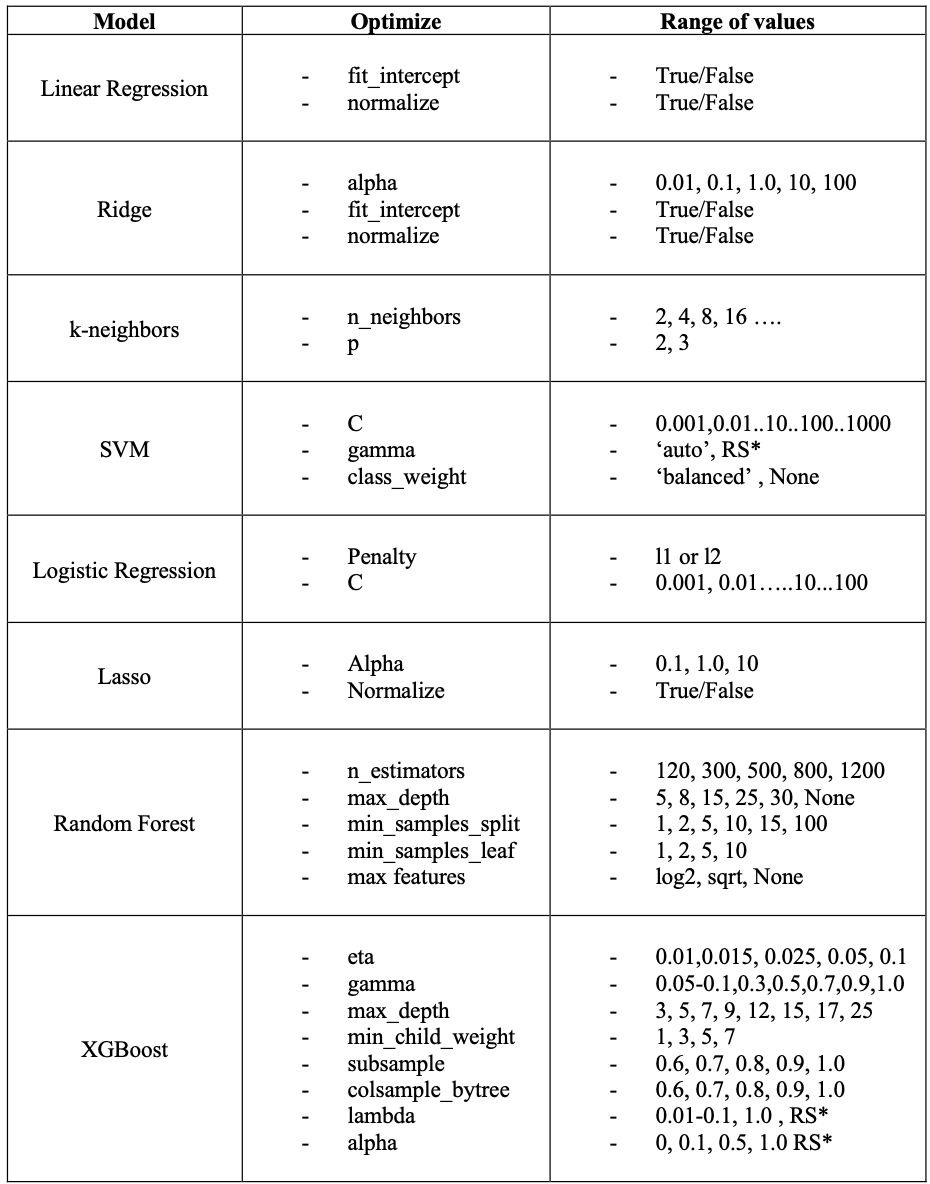

## Optuna

> Optuna handles almost everything you’ll do: mixed integer, float and categorical parameters, conditional search spaces, early pruning of bad trials, and good visualization. It’s actively maintained and works with any framework (sklearn, XGBoost, PyTorch). Its TPE sampler is better than random search at the same budget, and the code is shorter than the skopt equivalent.

Optuna has three objects: a study (one optimization run), a trial (one evaluation of a hyperparameter set), and an objective (your function, which takes a trial and returns a number)

The sampler. The default is TPE. After a random warm-up (10 trials by default), it splits past trials into a good group (roughly the top quarter by score) and a bad group, fits a density to each, and proposes points that are likely under the good density relative to the bad one. That is why it beats random search without the cubic cost of a Gaussian process.

In [59]:
open('rf_optuna.py' , 'a').close()

In [62]:
! pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 24.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 17.0 MB/s eta 0:00:00


In [64]:
print('Below code is generated by Claude for learning purpose')

Below code is generated by Claude for learning purpose


In [60]:
%%writefile rf_optuna.py
import pandas as pd
import optuna                              # the tuning library
from sklearn import ensemble               # RandomForestClassifier lives here
from sklearn import model_selection        # cross-validation tools


# The objective is the function Optuna calls once per trial.
# Optuna hands it a `trial` object; you ask that object for hyperparameter
# values, train a model with them, and return a score.
# Optuna then tries to make that score as high as possible.
def objective(trial, x, y):

    # Each suggest_* call picks a value for one hyperparameter.
    # Early trials pick almost randomly; later trials use the scores of
    # earlier ones to pick smarter values.
    params = {
        # whole number between 100 and 1000
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),

        # whole number between 3 and 15 (depth 1-2 underfits this data)
        'max_depth': trial.suggest_int('max_depth', 3, 15),

        # pick one option from a list
        'criterion': trial.suggest_categorical('criterion', ['gini', 'entropy']),

        # decimal between 0.1 and 1.0: the fraction of features
        # each tree is allowed to consider at every split
        'max_features': trial.suggest_float('max_features', 0.1, 1.0),
    }

    # Build a random forest using the values Optuna just chose.
    # **params unpacks the dictionary into keyword arguments.
    # n_jobs=-1 uses all CPU cores; random_state makes results repeatable.
    model = ensemble.RandomForestClassifier(**params, n_jobs=-1, random_state=42)

    # 5-fold cross-validation that keeps class proportions equal in each fold.
    # shuffle + random_state means every trial sees the SAME folds, so score
    # differences come from the hyperparameters and not from the split.
    kf = model_selection.StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    # Trains on 4 folds, scores on the 5th, five times over.
    # Returns an array of 5 accuracies.
    scores = model_selection.cross_val_score(
        model, x, y, cv=kf, scoring='accuracy'
    )

    # Return the mean accuracy. Optuna maximizes this number,
    # so (unlike hyperopt/skopt) there is no need to negate it.
    return scores.mean()


# This block runs only when you execute the file directly.
if __name__ == '__main__':

    # Load the data and split into features (X) and target (y).
    df = pd.read_csv('/content/drive/MyDrive/Projects/Mobile Price Pred/train.csv')
    X = df.drop('price_range', axis=1)
    y = df.price_range

    # A study is one whole tuning run. direction='maximize' because
    # our objective returns accuracy (higher is better).
    # The seeded sampler makes the search itself repeatable.
    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=42),
    )

    # Run 30 trials. optimize() expects a function that takes only `trial`,
    # so the lambda passes X and y through to our objective.
    study.optimize(lambda trial: objective(trial, X, y), n_trials=30)

    # Results: best_value is the best mean CV accuracy found,
    # best_params is the dict of hyperparameters that produced it.
    print('Best accuracy:', study.best_value)
    print('Best params  :', study.best_params)
    optuna.visualization.plot_param_importances(study)

Overwriting rf_optuna.py


In [63]:
!python rf_optuna.py

[I 2026-10-13 09:57:12,497] A new study created in memory with name: no-name-c93b1cab-ec2c-4022-bc31-ea1ab7953112
[I 2026-10-13 09:57:34,882] Trial 0 finished with value: 0.8895 and parameters: {'n_estimators': 437, 'max_depth': 15, 'criterion': 'gini', 'max_features': 0.24041677639819287}. Best is trial 0 with value: 0.8895.
[I 2026-10-13 09:57:43,112] Trial 1 finished with value: 0.789 and parameters: {'n_estimators': 240, 'max_depth': 3, 'criterion': 'gini', 'max_features': 0.737265320016441}. Best is trial 0 with value: 0.8895.
[I 2026-10-13 09:57:46,823] Trial 2 finished with value: 0.891 and parameters: {'n_estimators': 118, 'max_depth': 15, 'criterion': 'gini', 'max_features': 0.26364247048639056}. Best is trial 2 with value: 0.891.
[I 2026-10-13 09:57:52,313] Trial 3 finished with value: 0.877 and parameters: {'n_estimators': 265, 'max_depth': 6, 'criterion': 'gini', 'max_features': 0.36210622617823773}. Best is trial 2 with value: 0.891.
[I 2026-10-13 09:58:09,148] Trial 4 fin

## Summary

###Idea
Hyperparameters control how a model trains (learning rate, tree depth, number of trees). Parameters are what the model learns (slopes, biases). Tuning searches for the hyperparameter combination that scores best under cross-validation.

## Methods

### Grid search
Tries every combination from lists you provide: 6 n_estimators × 6 , max_depth × 2 , criteria × 5 folds = 360 fits. Exhaustive and simple, but cost multiplies with each added parameter.

### Randomized search
Samples a fixed number of combinations (20 here) from ranges. You control the budget directly, and it tests more distinct values per parameter than a grid of the same cost.

### gp_minimize (scikit-optimize)
Bayesian optimization with a Gaussian process. It models score as a function of the hyperparameters and uses that model to choose the next point. Optimizers minimize, so the objective returns negative accuracy. The space is defined with space.Integer, Real and Categorical.

### Hyperopt
Uses TPE, which models good and bad trials separately and samples where good ones are likely. The space is declared up front with hp.quniform, hp.uniform and hp.choice ,  with scope.int for integers.

### Optuna
The space is declared inside the objective with trial.suggest_*. A study runs the trials and stores results. Supports pruning, conditional spaces, and returns real values in best_params. Actively maintained and works with any framework.

## Takeaways
- Hand tuning first builds intuition for how parameters interact
